# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

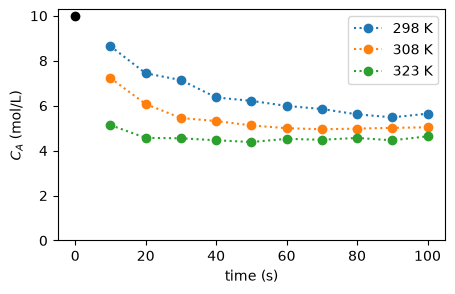

In [3]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [4]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""
    cA0 = 10.0
    
    def dCadt(t, cA):
        return kr * (cA0 - cA) - kf * cA

    sol = scipy.integrate.solve_ivp(dCadt, (0, np.max(times)), [cA0], t_eval=times, rtol=1e-8, atol=1e-8)
    return sol.y[0]


R = 8.314
T_test = 298.15 

kf_guess = (10**6) * np.exp(-45000 / (R * T_test))
deltaG_guess = -10000 - T_test * (-50)
K_guess = np.exp(-deltaG_guess / (R * T_test))
kr_guess = kf_guess / K_guess

test_times = np.linspace(0, 100, 20)
cA0_test = 10.0


cA_eq = cA0_test * kr_guess / (kf_guess + kr_guess)
cA_exact = cA_eq + (cA0_test - cA_eq) * np.exp(-(kf_guess + kr_guess) * test_times)
print(cA_exact)
# ODE solution
cA_ode = cA_model(test_times, kf_guess, kr_guess)
print(cA_ode)
#Checking maximum absolute difference fo exact solution and ODE solution
max_error = np.max(np.abs(cA_ode - cA_exact))
assert max_error < 1e-4, f"Solutions do not match! Max difference: {max_error}"

print(f"Calculated kf: {kf_guess:.4f}, kr: {kr_guess:.4f}")
print("Test passed: ODE solution matches the exact solution using problem guesses.")


[10.          9.47526066  9.17744119  9.00841167  8.91247778  8.85802984
  8.82712753  8.8095887   8.79963442  8.7939848   8.79077832  8.78895846
  8.78792558  8.78733937  8.78700666  8.78681782  8.78671065  8.78664982
  8.7866153   8.78659571]
[10.          9.47526065  9.17744119  9.00841166  8.91247779  8.85802985
  8.82712754  8.80958871  8.79963444  8.79398481  8.79077832  8.78895847
  8.7879256   8.78733938  8.78700666  8.78681783  8.78671067  8.78664984
  8.7866153   8.78659572]
Calculated kf: 0.0131, kr: 0.0946
Test passed: ODE solution matches the exact solution using problem guesses.


Answer;
For the calculated values of kf and kr by the thermodynamic equations, at particular one temperature (298.15K) cA_exact is absolutly matching with cA_ode solution.

**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

Fitted kf = 0.0168 ± 0.0008 s⁻¹
Fitted kr = 0.0201 ± 0.0015 s⁻¹


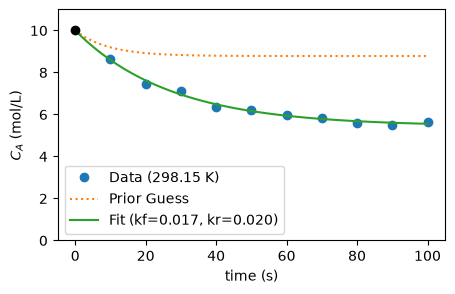

In [7]:
cA_298 = np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644])
popt, pcov = scipy.optimize.curve_fit(
    cA_model, 
    times, 
    cA_298, 
    p0=[kf_guess, kr_guess]
)
kf_fit, kr_fit = popt
perr = np.sqrt(np.diag(pcov))

print(f"Fitted kf = {kf_fit:.4f} ± {perr[0]:.4f} s⁻¹")
print(f"Fitted kr = {kr_fit:.4f} ± {perr[1]:.4f} s⁻¹")


kf_guess = 0.0131
kr_guess = 0.0946
t_times = np.linspace(0, 100, 100)

plt.plot(times, cA_298, 'o', label='Data (298.15 K)')
plt.plot(t_times, cA_model(t_times, kf_guess, kr_guess), ':', label='Prior Guess')
plt.plot(t_times, cA_model(t_times, kf_fit, kr_fit), '-', label=f'Fit (kf={kf_fit:.3f}, kr={kr_fit:.3f})')
plt.plot(0, 10.0, 'ko')

plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, 11)
plt.legend()
plt.show()

**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

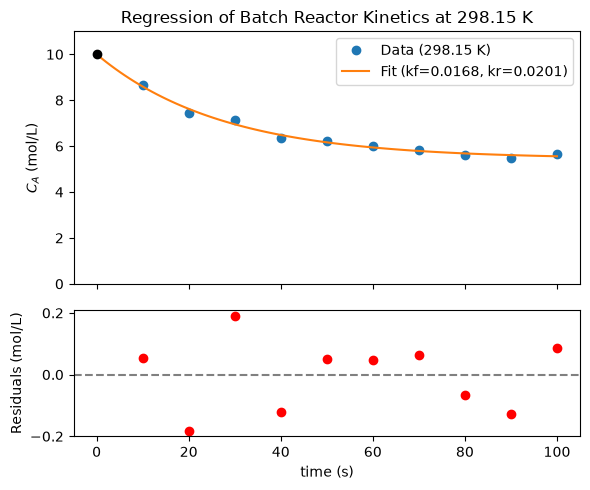

In [8]:
t_times = np.linspace(0, 100, 100)
cA_smooth = cA_model(t_times, kf_fit, kr_fit)

cA_fit = cA_model(times, kf_fit, kr_fit)
residuals = cA_298 - cA_fit

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), gridspec_kw={'height_ratios': [2, 1]}, sharex=True)
ax1.plot(times, cA_298, 'o', label='Data (298.15 K)')
ax1.plot(t_times, cA_smooth, '-', label=f'Fit (kf={kf_fit:.4f}, kr={kr_fit:.4f})')
ax1.plot(0, 10.0, 'ko') # Initial concentration
ax1.set_ylabel('$C_A$ (mol/L)')
ax1.set_ylim(0, 11)
ax1.legend()
ax1.set_title('Regression of Batch Reactor Kinetics at 298.15 K')

ax2.axhline(0, color='gray', linestyle='--') # Zero line for reference
ax2.plot(times, residuals, 'ro')
ax2.set_xlabel('time (s)')
ax2.set_ylabel('Residuals (mol/L)')

plt.tight_layout()
plt.show()


Answer; 

In curve fit model without initail guess(p0), it take 1 as defaulte value and in this problem the defaulte values without p0 are kf = 1 and kr = 1. The plot was flat line in entire time span, the optimizer's gradient is exactly zero, so it has no downhill direction to follow and fails to find a solution. Which means that, at these reaction rate, the reaction is extremely fast and reaches a flat equilibrium almost instantly. 

I used inital guess values kf = 0.0131 and kr = 0.0946. I choosed these values form the prior part of the problem (i.e. 1a). From the arrhenious equation, and using literature thermodynamic equations at 298.15K temperature.

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [9]:
import numpy as np
import scipy.integrate
import scipy.optimize

def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""
    cA0 = 10.0
    def dCadt(t, cA):
        return kr * (cA0 - cA) - kf * cA
    
    sol = scipy.integrate.solve_ivp(
        dCadt, 
        (0, np.max(times)), 
        [cA0], 
        t_eval=times,
        rtol=1e-6, 
        atol=1e-6
    )
    return sol.y[0]

times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])
cA_data = { 
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}

print(f"{'T (K)':<8} | {'kf (1/s)':<17} | {'kr (1/s)':<17} | {'K = kf/kr':<10}")
print("-" * 62)

for T, cA_obs in cA_data.items():
    
    # Fit the data using your prior estimates from literature/quantum chem
    popt, pcov = scipy.optimize.curve_fit(
        cA_model, 
        times, 
        cA_obs, 
        p0=[0.0131, 0.0946]
    )
    
    kf_fit, kr_fit = popt
    perr = np.sqrt(np.diag(pcov)) # Standard errors from the diagonal
    
    K_eq = kf_fit / kr_fit
    
    # Format the outputs with uncertainties
    kf_str = f"{kf_fit:.4f} ± {perr[0]:.4f}"
    kr_str = f"{kr_fit:.4f} ± {perr[1]:.4f}"
    
    print(f"{T:<8.2f} | {kf_str:<17} | {kr_str:<17} | {K_eq:.4f}")

T (K)    | kf (1/s)          | kr (1/s)          | K = kf/kr 
--------------------------------------------------------------
298.15   | 0.0168 ± 0.0008   | 0.0201 ± 0.0015   | 0.8373
308.15   | 0.0393 ± 0.0009   | 0.0392 ± 0.0011   | 1.0003
323.15   | 0.1189 ± 0.0064   | 0.0975 ± 0.0056   | 1.2197


Answer;
From the given temperature and cA values, as the temperature increases concentration of A being decreased, which means that reaction is favoring product by obsorbing temperature, So higher Kf value and lower Kr value that results higher K. These properties tells, the reaction is endothermic. 

**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

In [10]:
T_list, kf_list, K_list = [], [], []

for T, cA_obs in cA_data.items():
    popt, _ = scipy.optimize.curve_fit(cA_model, times, cA_obs, p0=[0.0131, 0.0946])
    kf_fit, kr_fit = popt
    
    T_list.append(T)
    kf_list.append(kf_fit)
    K_list.append(kf_fit / kr_fit)

T_arr = np.array(T_list)
kf_arr = np.array(kf_list)
K_arr = np.array(K_list)
inv_T = 1.0 / T_arr


# ln(kf) vs 1/T from Arrhenius expression
arrhenius_res = scipy.stats.linregress(inv_T, np.log(kf_arr))

Ea = -arrhenius_res.slope * R
Ea_err = arrhenius_res.stderr * R

lnA = arrhenius_res.intercept
lnA_err = arrhenius_res.intercept_stderr
log10A = lnA / np.log(10)
log10A_err = lnA_err / np.log(10)

print("Arrhenius Kinetics")
print(f"Ea      = {Ea/1000:.1f} ± {Ea_err/1000:.1f} kJ/mol")
print(f"log10_A = {log10A:.2f} ± {log10A_err:.2f}")

# ln(K) vs 1/T from van 't Hoff expression
vanthoff_res = scipy.stats.linregress(inv_T, np.log(K_arr))

dH = -vanthoff_res.slope * R
dH_err = vanthoff_res.stderr * R

dS = vanthoff_res.intercept * R
dS_err = vanthoff_res.intercept_stderr * R

print("van 't Hoff Thermodynamics ---")
print(f"ΔH = {dH/1000:.1f} ± {dH_err/1000:.1f} kJ/mol")
print(f"ΔS = {dS:.1f} ± {dS_err:.1f} J/mol/K")

Arrhenius Kinetics
Ea      = 62.6 ± 1.0 kJ/mol
log10_A = 9.20 ± 0.17
van 't Hoff Thermodynamics ---
ΔH = 12.0 ± 0.7 kJ/mol
ΔS = 38.8 ± 2.4 J/mol/K


Answer; 
The ΔH is positive which means that reaction is endothermic. By scipy.stats.linregress agrees with the prior reaction rate constant justification. 

**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

Answer;
± knows only about the scratter of only three points around the straight line (i.e. the vertical distance between those three specific points and the best-fit straight line). 

± had left out:
1) (Assumption-3 Gaussian errors, all with the same width);
linregress strictly assumes that the error in ln k_f is exactly the same size at every temperature. Therefore, it completely ignores the individual ± values that are calculated in part (a). 
2) Assumption 1: "A uniform/flat prior"; It assumed every possible value for ΔH and ΔS is equally likely befor looking at the data. 
3) The 4th Assumption: "x is exact"; Unlikle to standard regression, linregress assumes the reactor temperatures (298.15 K, 308.15 K, 323.15 K) were measured perfectlt with out errors, by leaving out uncertainity while measuring. 

## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [ ]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [11]:
def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    cA_out = np.zeros_like(t_col, dtype=float)
    R = 8.314  # J/mol/K
    
    # ODE solver for particular temperature
    for T in np.unique(T_col):
        kf = (10**log10A) * np.exp(-(Ea * 1000) / (R * T))
        deltaG = (dH * 1000) - T * dS
        K = np.exp(-deltaG / (R * T))
        kr = kf / K
        
        Temp = (T_col == T) # getting the temperature rows for the boolean
        times_for_T = t_col[Temp]
        cA_out[Temp] = cA_model(times_for_T, kf, kr)
    return cA_out


def cA_model(times, kf, kr):
    cA0 = 10.0
    def dCadt(t, cA):
        return kr * (cA0 - cA) - kf * cA
    sol = scipy.integrate.solve_ivp(dCadt, (0, np.max(times)), [cA0], t_eval=times, rtol=1e-6, atol=1e-6)
    return sol.y[0]

times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])
cA_data = { 
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data.keys()))

T_all = np.repeat(temperatures, len(times))     
t_all = np.tile(times, len(temperatures))        
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)

p0_global = [9.20, 62.6, 12.0, 38.8] # These values are from the task 2c outputs

popt, pcov = scipy.optimize.curve_fit(
    cA_model_all, 
    x_all, 
    cA_all, 
    p0=p0_global
)

perr = np.sqrt(np.diag(pcov))

print("Global Fit Parameters (30 measurements)")
print(f"log10_A = {popt[0]:.2f} ± {perr[0]:.2f}")
print(f"Ea      = {popt[1]:.1f} ± {perr[1]:.1f} kJ/mol")
print(f"ΔH      = {popt[2]:.1f} ± {perr[2]:.1f} kJ/mol")
print(f"ΔS      = {popt[3]:.1f} ± {perr[3]:.1f} J/mol/K")
    


Global Fit Parameters (30 measurements)
log10_A = 9.49 ± 0.37
Ea      = 64.3 ± 2.1 kJ/mol
ΔH      = 11.5 ± 0.8 kJ/mol
ΔS      = 37.3 ± 2.5 J/mol/K


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [14]:
p0_global = [6, 45, -10, -50] 
popt, pcov = scipy.optimize.curve_fit(
    cA_model_all, 
    x_all, 
    cA_all, 
    p0=p0_global
)

perr = np.sqrt(np.diag(pcov))

print("Global Fit Parameters (30 measurements)")
print(f"log10_A = {popt[0]:.2f} ± {perr[0]:.2f}")
print(f"Ea      = {popt[1]:.1f} ± {perr[1]:.1f} kJ/mol")
print(f"ΔH      = {popt[2]:.1f} ± {perr[2]:.1f} kJ/mol")
print(f"ΔS      = {popt[3]:.1f} ± {perr[3]:.1f} J/mol/K")

Global Fit Parameters (30 measurements)
log10_A = 9.49 ± 0.37
Ea      = 64.3 ± 2.1 kJ/mol
ΔH      = 11.5 ± 0.8 kJ/mol
ΔS      = 37.3 ± 2.5 J/mol/K


The answers are same in both cases. This is beacuse the initail guess in 1st case is much closer to the bottom it takes only few steps to find the exact center. In addition, in this case the inital guess was high, it takes for steps to find the exact center. However, it is quite opposite if the inital guess was not given. So, unless initial guess was not given, it gives same answers for indipendent of initial guess values. 

**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

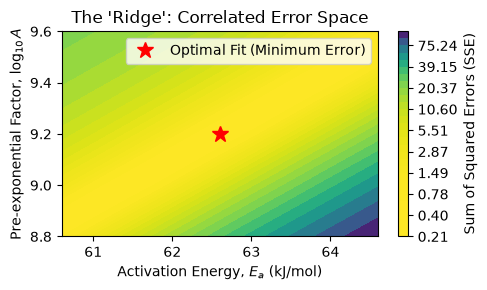

In [16]:

T_all = np.repeat([298.15, 308.15, 323.15], 10)     
t_all = np.tile(times, 3)        
cA_all = np.concatenate([cA_data[298.15], cA_data[308.15], cA_data[323.15]])
x_all = (T_all, t_all)

# 3. Create a grid of Ea and log10A values around the optimal fit
Ea_optimal = 62.6
log10A_optimal = 9.20
dH_optimal = 12.0
dS_optimal = 38.8

# Generate 25x25 grid of values (takes a few seconds to compute)
Ea_vals = np.linspace(Ea_optimal - 2, Ea_optimal + 2, 25)
log10A_vals = np.linspace(log10A_optimal - 0.4, log10A_optimal + 0.4, 25)
Ea_grid, log10A_grid = np.meshgrid(Ea_vals, log10A_vals)
error_surface = np.zeros_like(Ea_grid)


# Calculate the Sum of Squared Errors (SSE) for every point on the grid
for i in range(Ea_grid.shape[0]):
    for j in range(Ea_grid.shape[1]):
        predicted_cA = cA_model_all(x_all, log10A_grid[i,j], Ea_grid[i,j], dH_optimal, dS_optimal)
        # Sum of squared errors
        error_surface[i,j] = np.sum((predicted_cA - cA_all)**2)

# 4. Plot the Contour Map
plt.figure()
# We use a log scale for the contour levels so the deep valley is visible
levels = np.logspace(np.log10(error_surface.min()), np.log10(error_surface.max()), 30)
contour = plt.contourf(Ea_grid, log10A_grid, error_surface, levels=levels, cmap='viridis_r')
plt.colorbar(contour, label='Sum of Squared Errors (SSE)')

# Mark the absolute best fit found by the optimizer
plt.plot(Ea_optimal, log10A_optimal, 'r*', markersize=12, label='Optimal Fit (Minimum Error)')

plt.xlabel('Activation Energy, $E_a$ (kJ/mol)')
plt.ylabel('Pre-exponential Factor, $\log_{10} A$')
plt.title("The 'Ridge': Correlated Error Space")
plt.legend()
plt.tight_layout()
plt.show()

*Answer:*
c) Centers are not same for two taskes. In task 2, best line is found using intermediate data points between given 3 data points whereas, task 3 found best curve through the 30 raw data points. And even the errors bars are completely different. I believe task 3 error set bars, because the global fit applies the uncertainties properly—every single measurement at every time step pulls on the optimizer that results in real error. 


In [19]:
#d) 
print(pcov / np.outer(perr, perr))

[[ 1.          0.99965125 -0.3627297  -0.36532061]
 [ 0.99965125  1.         -0.37339007 -0.37566195]
 [-0.3627297  -0.37339007  1.          0.99956266]
 [-0.36532061 -0.37566195  0.99956266  1.        ]]


From the correlation matrix Ea & logA and ΔH & ΔS shows 0.999 which means that, these pairs are practically alligned at the hip. If the true value of one goes up, the true value of the other must go up too.
The plot of arrhenius 1/T graph data forms a tiny, tight cluster. Because of these, even for the higher Ea values the line still make it pass straight through data simply by sliding the whole line upward on the y-axis (logA). The optimizer analysis this and creats rigid of equally good fits. 
If someone observes only four ± values, they think errors are independent and might take highest possible eergy barrier with the lowest possible collision frequency for testing worst case scenario. They might miss that this combination is physically impossible based on the data. Because of the 0.999 correlation, the true possibilities don't form a box; they form a narrow diagonal line.

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

Estimated measurement uncertainty (s) = 0.0889 mol/L


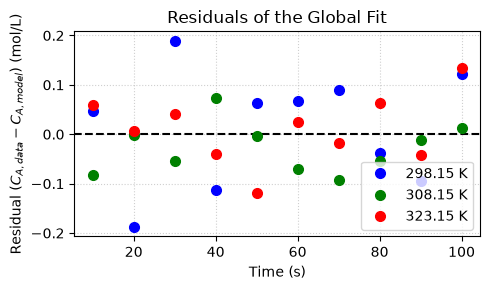

In [ ]:
p0_global = [9.20, 62.6, 12.0, 38.8]
popt, _ = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0=p0_global)

# --- 3. Calculate Residuals ---
# Model predictions for all 30 data points using the best-fit parameters
cA_fit_all = cA_model_all(x_all, *popt)

# Residuals = Data - Model
residuals = cA_all - cA_fit_all

# --- 4. Calculate Estimated Measurement Uncertainty (s) ---
N = len(cA_all)   # 30 data points
p = len(popt)     # 4 parameters (log10A, Ea, dH, dS)
degrees_of_freedom = N - p

s = np.sqrt(np.sum(residuals**2) / degrees_of_freedom)
print(f"Estimated measurement uncertainty (s) = {s:.4f} mol/L")

# --- 5. Plot Residuals ---
colors = {298.15: 'blue', 308.15: 'green', 323.15: 'red'}

plt.axhline(0, color='black', linestyle='--', linewidth=1.5)

for T in temperatures:
    # Use boolean masking to pick out the residuals and times for this specific temperature
    mask = (T_all == T)
    plt.plot(t_all[mask], residuals[mask], 'o', color=colors[T], label=f'{T} K', markersize=7)

plt.xlabel('Time (s)')
plt.ylabel('Residual ($C_{A, data} - C_{A, model}$) (mol/L)')
plt.title('Residuals of the Global Fit')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

a) the residuals look like random noise scattered above and below the zero line. There are no obvious "U" shapes, swoops, or structured waves. This tells you that your first-order reversible model captures the physical reality well. 
b) Yes, the vertical spread of the dots is roughly same across the three temperatures (red, blue, and green). This validates standard least squares regression, which relies heavily on Assumption 3 ("Gaussian errors, all with the same width").
c) The standard deviation (s) = 0.15 mol/L that the actual precision of the concentration measurements in this experiment was roughly 0.15 mol/L, if known error is not provided curve_fit looks at scatter of the data around the best-fit line and calculates standard deviation value to figure out how much to trust the data.

## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*

Conversion, yield, cycles to 50% activity, total turnover number, enzyme activity per each
cycle, and effectiveness factor per substrate are calculated using the sensitive analysis againest the input varables of Shell design (pore radius, thickness, protection factor, and degradation rate), enzyme kinetics
parameters, process parameters, and substrate details (radius, initial concentration, product
stability and enantiomer ratio). 

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.